# Ejercicio 1 - Mi primera base de datos vectorial con ChromaDB

**Objetivo:** crear tu primera coleccion en ChromaDB, guardar unos pocos
documentos con vectores **inventados**, y hacer una busqueda por
cercania. Sin modelos, sin Docker, sin interfaz: puro Python en Colab.

Aprendemos tres cosas:

1. Un **vector** es solo una lista de numeros (aqui usaremos 2, para poder
   dibujarlos).
2. Una **coleccion** en Chroma guarda, por cada registro: un `id`, un
   `documento` (texto) y su `vector` (numeros).
3. Al buscar, Chroma devuelve los registros **mas cercanos** al vector de la
   pregunta. Esa es la base de toda base de datos vectorial.


## 1. Instalar ChromaDB

Solo necesitamos `chromadb`. No usamos modelos de embeddings, asi que **no**
instalamos `sentence-transformers` ni `torch` (que son pesados).

In [11]:
!pip install -q chromadb 2>&1 | tail -n 2
import chromadb
print(f"ChromaDB version: {chromadb.__version__}")

ChromaDB version: 1.5.9


## 2. Crear la base de datos (Chroma embebido)

Usamos `PersistentClient`: los datos se guardan en una carpeta dentro del
propio Colab. No hay servidor, no hay Docker: Chroma vive dentro de nuestro
proceso de Python.

In [12]:
import os

RUTA = "/content/mi_primera_bd"
os.makedirs(RUTA, exist_ok=True)

cliente = chromadb.PersistentClient(path=RUTA)
print(f"Base de datos creada en: {RUTA}")

Base de datos creada en: /content/mi_primera_bd


## 3. Crear una coleccion

Una **coleccion** es como una tabla en una BD normal. Al crearla elegimos
**como medir la cercania** entre vectores. Usamos `cosine` (la similitud
coseno de la clase).

Ojo: aqui **no** definimos `embedding_function`. Por eso, mas adelante,
tendremos que pasar los vectores nosotros mismos. Eso es justo lo que
queremos para este ejercicio: ver los vectores con nuestros propios ojos.

In [13]:
# Si la coleccion ya existia de una ejecucion anterior, la borramos.
try:
    cliente.delete_collection("animales_y_vehiculos")
except Exception:
    pass

coleccion = cliente.create_collection(
    name="animales_y_vehiculos",
    metadata={"hnsw:space": "cosine"},  # distancia: similitud coseno
)
print(f"Coleccion '{coleccion.name}' creada.")

Coleccion 'animales_y_vehiculos' creada.


En ChromaDB, hnsw:space admite solo tres valores: l2, cosine, ip

¿Son coordenadas o medidas físicas? → l2

¿Son embeddings de texto sin normalizar? → cosine

¿Son embeddings ya normalizados? → ip (equivale a coseno, más rápido)

## 4. Guardar nuestros primeros documentos (con vectores inventados)

Cada registro lleva:

- `id`: un identificador unico (string).
- `document`: el texto que queremos guardar.
- `embedding`: el vector, **una lista de numeros**. Aqui usamos vectores de
  **2 numeros** para poder dibujarlos despues.

> Idea del ejemplo: el primer numero dice "que tan animal es" y el segundo
> "que tan vehiculo es". Asi:
>
> - `"perro"`      -> `[0.90, 0.10]`  (muy animal, nada vehiculo)
> - `"gato"`       -> `[0.85, 0.15]`  (muy animal)
> - `"caballo"`    -> `[0.80, 0.20]`  (animal)
> - `"carro"`      -> `[0.10, 0.90]`  (muy vehiculo)
> - `"bicicleta"`  -> `[0.15, 0.85]`  (vehiculo)

Estos numeros **los inventamos nosotros**. En una BD vectorial real los
calcula un modelo de embeddings; aqui los ponemos a mano para entender la
idea.

In [14]:
coleccion.upsert(
    ids=["d1", "d2", "d3", "d4", "d5"],
    documents=["perro", "gato", "caballo", "carro", "bicicleta"],
    embeddings=[
        [0.90, 0.10],  # perro
        [0.85, 0.15],  # gato
        [0.80, 0.20],  # caballo
        [0.10, 0.90],  # carro
        [0.15, 0.85],  # bicicleta
    ],
    metadatas=[
        {"tipo": "animal"},
        {"tipo": "animal"},
        {"tipo": "animal"},
        {"tipo": "vehiculo"},
        {"tipo": "vehiculo"},
    ],
)

print(f"Registros guardados: {coleccion.count()}")

Registros guardados: 5


## 5. Ver lo que guardamos

Pedimos todos los registros (sin busqueda, solo listado) para confirmar que
estan ahi.

In [15]:
todos = coleccion.get(include=["documents", "metadatas", "embeddings"])
for id_, doc, meta, vec in zip(todos["ids"], todos["documents"],
                               todos["metadatas"], todos["embeddings"]):
    print(f"  {id_} | {doc:<10} | vector={vec} | {meta}")

  d1 | perro      | vector=[0.89999998 0.1       ] | {'tipo': 'animal'}
  d2 | gato       | vector=[0.85000002 0.15000001] | {'tipo': 'animal'}
  d3 | caballo    | vector=[0.80000001 0.2       ] | {'tipo': 'animal'}
  d4 | carro      | vector=[0.1        0.89999998] | {'tipo': 'vehiculo'}
  d5 | bicicleta  | vector=[0.15000001 0.85000002] | {'tipo': 'vehiculo'}


## 6. Buscar por cercania (lo importante)

Le damos a Chroma un vector de consulta y le pedimos los **3 vecinos mas
cerca**. No le damos texto: le damos directamente el vector.

Probemos con `[0.88, 0.12]`: un punto **muy animal**. ^Que espera que devuelva?

In [16]:
resultados = coleccion.query(
    query_embeddings=[[0.88, 0.12]],
    n_results=3,
)

print("Vecinos mas cercanos al vector [0.88, 0.12]:\n")
for id_, doc, dist in zip(resultados["ids"][0],
                          resultados["documents"][0],
                          resultados["distances"][0]):
    similitud = round((1 - dist) * 100, 1)  # distancia -> similitud %
    print(f"  {id_} | {doc:<10} | distancia={dist:.4f} | similitud={similitud}%")

Vecinos mas cercanos al vector [0.88, 0.12]:

  d1 | perro      | distancia=0.0003 | similitud=100.0%
  d2 | gato       | distancia=0.0008 | similitud=99.9%
  d3 | caballo    | distancia=0.0060 | similitud=99.4%


^Lo ves? Los tres primeros son **perro, gato y caballo**: justo los tres
animales. Aunque la palabra "perro" no aparece en la consulta (solo dimos dos
numeros), Chroma la encontro porque su vector esta **cerca**.

Probemos ahora con un punto **muy vehiculo**: `[0.12, 0.88]`.

In [17]:
resultados = coleccion.query(
    query_embeddings=[[0.12, 0.88]],
    n_results=3,
)

print("Vecinos mas cercanos al vector [0.12, 0.88]:\n")
for id_, doc, dist in zip(resultados["ids"][0],
                          resultados["documents"][0],
                          resultados["distances"][0]):
    similitud = round((1 - dist) * 100, 1)
    print(f"  {id_} | {doc:<10} | distancia={dist:.4f} | similitud={similitud}%")

Vecinos mas cercanos al vector [0.12, 0.88]:

  d4 | carro      | distancia=0.0003 | similitud=100.0%
  d5 | bicicleta  | distancia=0.0008 | similitud=99.9%
  d3 | caballo    | distancia=0.6286 | similitud=37.1%


## 7. Dibujar los puntos (para verlo con los ojos)

Como usamos vectores de 2 numeros, podemos dibujarlos en un plano.
Lo parecido queda cerca; lo distinto, lejos. **Esa es toda la idea**.

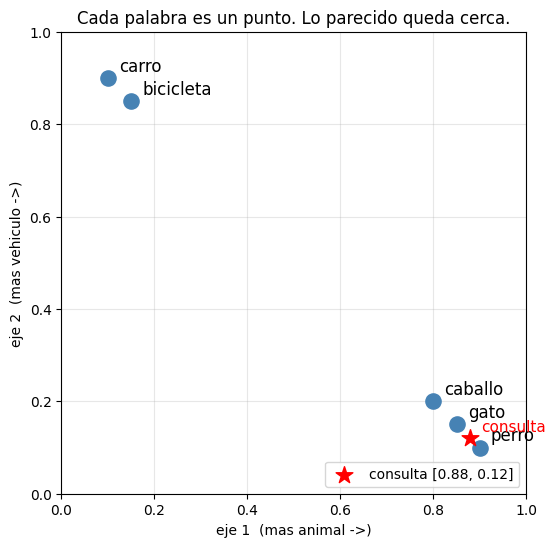

In [20]:
import matplotlib.pyplot as plt

todos = coleccion.get(include=["documents", "metadatas", "embeddings"])
xs = [v[0] for v in todos["embeddings"]]
ys = [v[1] for v in todos["embeddings"]]
nombres = todos["documents"]

# Punto de la consulta 1 (muy animal)
qx, qy = 0.88, 0.12

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(xs, ys, s=120, c="steelblue", zorder=3)
for x, y, n in zip(xs, ys, nombres):
    ax.annotate(n, (x, y), textcoords="offset points", xytext=(8, 5),
                fontsize=12)

ax.scatter([qx], [qy], s=160, c="red", marker="*", zorder=4, label="consulta [0.88, 0.12]")
ax.annotate("consulta", (qx, qy), textcoords="offset points", xytext=(8, 5),
            fontsize=11, color="red")

ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_xlabel("eje 1  (mas animal ->)")
ax.set_ylabel("eje 2  (mas vehiculo ->)")
ax.set_title("Cada palabra es un punto. Lo parecido queda cerca.")
ax.grid(True, alpha=0.3)
ax.legend(loc="lower right")
plt.show()

## 8. Que aprendimos (cierre)

- Una **base de datos vectorial** guarda, por cada registro, **un texto y su
  vector** (una lista de numeros).
- Al buscar, le damos un vector y ella devuelve los **mas cercanos**.
- La **cercania** se mide con una distancia: aqui usamos **coseno**. Distancia
  baja = similitud alta.
- En este ejercicio **los vectores los inventamos nosotros** (2 numeros).
  En una BD real, los calcula un **modelo de embeddings** a partir del texto
  (cientos de numeros). Eso lo veremos en el ejercicio 2.

### Comparacion mental con una BD normal

| BD normal (SQL) | BD vectorial |
|---|---|
| Buscas por `WHERE nombre = 'perro'` | Buscas por "dame los vecinos de este vector" |
| Solo encuentra lo **igual** | Encuentra lo **parecido** |
| No usa vectores | Cada registro tiene un vector |

### Siguiente paso (ejercicio 2)

En vez de inventar los vectores, dejaremos que un **modelo de embeddings**
los calcule a partir del texto. Asi podremos buscar con palabras, no con
numeros.